# 🧪 CodeBroker Report Quality Evaluator
### **Automated Meta-Assessment & Cross-Model LLM-as-a-Judge (Gemini, Llama & Qwen)**

---

### 📌 Overview & Purpose
The **CodeBroker** agentic system automatically generates comprehensive assessment reports for code files, directories, or entire repositories. A standard CodeBroker report comprises four sections:
1. **Code Description**: Architectural summary and component breakdown.
2. **Code Correctness Assessment**: Functionality, security, resource efficiency, and test coverage scores (0–100%).
3. **Code Style Assessment**: Readability, maintainability, linting, and best practices scores (0–100%).
4. **Suggested Improvements**: Actionable guidance for functionality, style, and repository practices.

This notebook implements an **Automated Meta-Assessment Framework (LLM-as-a-Judge)** designed to evaluate the **quality, fidelity, and reliability of the generated CodeBroker reports**. It supports multi-model cross-evaluation using:
- **Google GenAI (`google-genai`)**: Powered by Gemini 2.5 Flash / Pro.
- **Ollama**: Runs local `llama3.2:1b` and `qwen2.5:1.5b` judges with schema-constrained JSON output validated by Pydantic.

All three judges evaluate the same codebase and report against identical evaluation dimensions, prompts, and weights. Each judge produces its own dedicated assessment report, enabling independent analysis and cross-model calibration.

### 📐 Evaluation Dimensions
The evaluator assesses the report across five critical dimensions:
- **Faithfulness & Grounding (25%)**: Are all observations and critiques strictly grounded in the real code, free from hallucinations or false bug attributions?
- **Completeness & Coverage (20%)**: Did the report evaluate all major components, core routines, security implications, and error pathways?
- **Actionability & Specificity (25%)**: Are the suggested improvements concrete, practical, and accompanied by specific instructions or file references?
- **Scoring Calibration & Consistency (15%)**: Do the numerical scores (0–100%) align realistically with the textual findings and actual code quality?
- **Structure & Schema Adherence (15%)**: Does the report strictly follow CodeBroker's structured 4-section architecture?

### 🛠️ Technology Stack
- **Google GenAI SDK (`google-genai`)**: Gemini models with native structured Pydantic schema validation.
- **Ollama HTTP API**: Local model inference via `/api/chat`, using Python standard-library HTTP support.
- **JAX (`jax.numpy`)**: High-performance mathematical scoring, vector dot products, delta vectors, and cosine similarity.
- **Polars (`polars`)**: Fast, structured tabular data management, score breakdowns, and cross-model comparison tables.
- **Matplotlib**: Visual analytics (single-model and comparative side-by-side charts) saved to `analytics_data/`.


In [19]:
"""Environment initialization and core dependency imports."""

import os
import re
import json
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Any

import dotenv
import matplotlib.pyplot as plt
import polars as pl
import jax
import jax.numpy as jnp
from pydantic import BaseModel, Field
from IPython.display import display, Markdown, HTML

from google import genai
from google.genai import types
import urllib.error
import urllib.request

EVALUATION_SEED = 42

# Load environment variables from repository root .env file
repo_root = Path("..").resolve()
dotenv_path = repo_root / ".env"
if dotenv_path.exists():
    dotenv.load_dotenv(dotenv_path)
    print(f"✅ Loaded environment variables from: {dotenv_path}")
else:
    dotenv.load_dotenv()
    print("ℹ️ Loaded default environment variables")

# 1. Initialize Google GenAI Client
google_api_key = os.getenv("GOOGLE_API_KEY") or os.getenv("GEMINI_API_KEY")
if not google_api_key:
    print("⚠️ Warning: Missing GOOGLE_API_KEY or GEMINI_API_KEY in environment.")
    google_client = None
else:
    google_client = genai.Client(api_key=google_api_key)
    print("🚀 Google GenAI Client initialized successfully.")

# 2. Configure the local Ollama endpoint
ollama_base_url = os.getenv("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/")
print(f"🦙 Ollama endpoint: {ollama_base_url}")
qwen_model_name = os.getenv("OLLAMA_QWEN_MODEL", "qwen2.5:1.5b")

print(f"⚡ JAX Version: {jax.__version__} | Polars Version: {pl.__version__}")


✅ Loaded environment variables from: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/.env
🚀 Google GenAI Client initialized successfully.
🦙 Ollama endpoint: http://localhost:11434
⚡ JAX Version: 0.11.2 | Polars Version: 1.36.0


## 1. Code and Report Ingestion Utilities

To conduct an objective evaluation, the evaluator inspects:
1. **The Ground Truth Source Code**: Either a single file, a directory of modules, or a cloned repository.
2. **The CodeBroker Report**: Extracted from Markdown files, raw strings, or compiled HTML reports.
3. **The Shared Evaluation Prompt**: Shared identically across all judge models to guarantee benchmark parity.


In [20]:
def load_source_code(target_path: str) -> Dict[str, str]:
    """Loads source code from a file or directory for ground truth inspection.

    Args:
        target_path: Path to a file or directory containing the code reviewed by CodeBroker.

    Returns:
        Dict mapping relative file paths to their string contents.

    Raises:
        FileNotFoundError: If the target path does not exist.
    """
    path_obj = Path(target_path).resolve()
    if not path_obj.exists():
        raise FileNotFoundError(f"Target code path does not exist: {target_path}")

    source_files: Dict[str, str] = {}
    if path_obj.is_file():
        try:
            with open(path_obj, "r", encoding="utf-8", errors="ignore") as f:
                source_files[path_obj.name] = f.read()
        except Exception as e:
            source_files[path_obj.name] = f"Error reading file: {e}"
        return source_files

    skip_dirs = {".git", "__pycache__", ".venv", "venv", ".pytest_cache", "node_modules", "dist", "build"}
    skip_exts = {".pyc", ".png", ".jpg", ".jpeg", ".pdf", ".zip", ".tar", ".gz", ".eps", ".mp4", ".so", ".bin"}

    for root, dirs, files in os.walk(path_obj):
        dirs[:] = [d for d in dirs if d not in skip_dirs]
        for file_name in files:
            ext = Path(file_name).suffix.lower()
            if ext in skip_exts:
                continue
            full_file_path = Path(root) / file_name
            rel_file_path = str(full_file_path.relative_to(path_obj))
            try:
                with open(full_file_path, "r", encoding="utf-8", errors="ignore") as f:
                    source_files[rel_file_path] = f.read()
            except Exception as e:
                source_files[rel_file_path] = f"Error reading file: {e}"

    return source_files


def load_code_broker_report(report_source: str) -> str:
    """Parses and extracts the markdown text from a CodeBroker report.

    Accepts a direct markdown string, a .md file path, or an HTML report file
    generated by CodeBroker (which embeds markdown in a `markdownText` variable).

    Args:
        report_source: File path (.html or .md) or raw report text.

    Returns:
        The markdown string content of the CodeBroker report.
    """
    path_obj = Path(report_source)
    if path_obj.is_file():
        with open(path_obj, "r", encoding="utf-8", errors="ignore") as f:
            content = f.read()

        if path_obj.suffix.lower() == ".html":
            # Extract markdown from CodeBroker template: var markdownText = `...`;
            match = re.search(r"var\s+markdownText\s*=\s*`([\s\S]*?)`;", content)
            if match:
                extracted = match.group(1).replace(r"\`", "`")
                return extracted.strip()
            # Fallback regex strip
            clean = re.sub(r"<[^>]+>", " ", content)
            return re.sub(r"\s+", " ", clean).strip()
        return content.strip()

    return report_source.strip()


def format_codebase_context(source_files: Dict[str, str], max_char_budget: int = 150_000) -> str:
    """Formats ingested source files into a structured markdown block for model context.

    Args:
        source_files: Dictionary mapping file paths to code contents.
        max_char_budget: Maximum character limit to keep context concise.

    Returns:
        Formatted markdown string representation of the codebase.
    """
    blocks = []
    total_chars = 0
    for path, code in sorted(source_files.items()):
        header = f"### File: `{path}`\n```\n"
        footer = "\n```\n"
        available = max_char_budget - total_chars - len(header) - len(footer)
        if available <= 0:
            blocks.append(f"\n> *[Truncated remaining files due to context budget]*\n")
            break

        snippet = code if len(code) <= available else code[:available] + "\n... [Content Truncated]"
        blocks.append(f"{header}{snippet}{footer}")
        total_chars += len(header) + len(snippet) + len(footer)

    return "\n".join(blocks)


def build_evaluation_prompt(
    source_code_dict: Dict[str, str],
    report_text: str,
    weights: Dict[str, float],
) -> str:
    """Constructs the unified evaluation prompt shared identically across all LLM judges.

    Ensures that Gemini, Llama, and Qwen evaluate the exact same prompt instructions,
    codebase context, report content, dimension definitions, and scoring weights.

    Args:
        source_code_dict: Ground truth source code files inspected by CodeBroker.
        report_text: The markdown text of the CodeBroker report under evaluation.
        weights: Dictionary mapping quality dimension names to relative importance weights.

    Returns:
        Complete evaluation prompt string.
    """
    code_context = format_codebase_context(source_code_dict)

    prompt = f"""You are a principal software engineer and expert meta-evaluator acting as an objective LLM Judge.
Your objective is to evaluate the QUALITY and ACCURACY of an automated Code Assessment Report generated by "CodeBroker".

You are provided with:
1. THE GROUND TRUTH CODEBASE (the exact files reviewed by CodeBroker).
2. THE CODEBROKER ASSESSMENT REPORT (the generated evaluation output).

----------------------------------------
[GROUND TRUTH CODEBASE]
{code_context}
----------------------------------------

----------------------------------------
[CODEBROKER REPORT UNDER EVALUATION]
{report_text}
----------------------------------------

### Meta-Evaluation Guidelines:
Carefully compare the CodeBroker report against the ground truth codebase across these 5 dimensions:

1. **Faithfulness & Grounding (Weight: {weights['faithfulness']})**:
   - Did CodeBroker accurately describe the code's real behavior, classes, and functions?
   - Did it invent features, falsely attribute bugs, or hallucinate non-existent files?
   - Score 90-100% if completely grounded; penalize heavily for any hallucination or false bug report.

2. **Completeness & Coverage (Weight: {weights['completeness']})**:
   - Did CodeBroker identify the primary purpose and critical architectural components?
   - Did it evaluate error handling, security, efficiency, and automated test presence?
   - Did it miss glaring vulnerabilities, critical bugs, or major modules?

3. **Actionability & Specificity (Weight: {weights['actionability']})**:
   - Are the suggested improvements concrete, specific, and actionable for developers?
   - Did it provide clear direction, naming specific functions, files, or patterns?
   - Penalize generic platitudes (e.g., "write better tests" or "improve readability" without specifics).

4. **Scoring Calibration & Consistency (Weight: {weights['scoring_calibration']})**:
   - Did CodeBroker provide Correctness % and Style % scores?
   - Are the scores calibrated with the actual state of the code and the written analysis?
   - For example, if critical bugs or lack of tests exist, is the correctness score realistically adjusted?

5. **Structure & Adherence (Weight: {weights['structure_adherence']})**:
   - Does the report follow CodeBroker's standard 4 sections:
     (1) Code Description, (2) Code Correctness Assessment, (3) Code Style Assessment, (4) Suggested Improvements?

Evaluate every dimension objectively and populate the structured schema.
"""
    return prompt


## 2. Evaluation Schema Definition (Pydantic & Structured Output)

We define a rigorous structured schema using **Pydantic**. This schema guarantees that Gemini, Llama, and Qwen return strictly typed, machine-readable quality assessments for each evaluation dimension, including specific strengths, weaknesses, and calibrated score values.


In [21]:
class DimensionScore(BaseModel):
    """Evaluation score and detailed qualitative critique for a single quality dimension."""

    score: float = Field(
        ge=0.0,
        le=100.0,
        description="Quality percentage score from 0.0 to 100.0 for this dimension."
    )
    weight: float = Field(
        ge=0.0,
        le=1.0,
        description="Relative importance weight between 0.0 and 1.0."
    )
    rationale: str = Field(
        description="Detailed explanation justifying the score given the ground-truth code."
    )
    strengths: List[str] = Field(
        default_factory=list,
        description="Specific aspects where the CodeBroker report accurately reflected the code."
    )
    weaknesses: List[str] = Field(
        default_factory=list,
        description="Gaps, inaccuracies, or missed insights in the CodeBroker report."
    )


class CodeBrokerQualityReport(BaseModel):
    """Comprehensive meta-assessment of a CodeBroker report's quality."""

    faithfulness: DimensionScore = Field(
        description="Faithfulness and grounding: Are claims strictly truthful to the inspected code?"
    )
    completeness: DimensionScore = Field(
        description="Coverage: Did CodeBroker assess the core modules, security, efficiency, and tests?"
    )
    actionability: DimensionScore = Field(
        description="Actionability: Are the suggested improvements specific, constructive, and practical?"
    )
    scoring_calibration: DimensionScore = Field(
        description="Calibration: Do CodeBroker's scores (Correctness % and Style %) accurately reflect code health?"
    )
    structure_adherence: DimensionScore = Field(
        description="Schema adherence: Did the report cleanly follow the required 4-part CodeBroker format?"
    )
    code_broker_scores_critique: str = Field(
        description="Direct critique comparing CodeBroker's reported scores with actual code reality."
    )
    identified_hallucinations_or_untrue_claims: List[str] = Field(
        default_factory=list,
        description="Specific claims in the CodeBroker report that are false or unsupported by the code."
    )
    critical_missed_issues: List[str] = Field(
        default_factory=list,
        description="Important bugs, security vulnerabilities, or code flaws that CodeBroker missed entirely."
    )
    executive_summary: str = Field(
        description="High-level executive evaluation summary of the CodeBroker report's quality."
    )
    recommendations_to_improve_code_broker: List[str] = Field(
        default_factory=list,
        description="Actionable guidance on how CodeBroker's prompting or pipeline can be improved."
    )


## 3. Google GenAI LLM-as-a-Judge Evaluation Engine

The Google GenAI evaluation engine leverages `google.genai` with `gemini-2.5-flash` (or `gemini-2.5-pro`). It invokes the shared grounded prompt and populates the `CodeBrokerQualityReport` schema via native structured output.


In [22]:
def evaluate_code_broker_report(
    source_code_dict: Dict[str, str],
    report_text: str,
    client: genai.Client,
    model_name: str = "gemini-2.5-flash",
    weights: Optional[Dict[str, float]] = None,
) -> CodeBrokerQualityReport:
    """Evaluates the quality of a CodeBroker report using Google Gemini as a grounded judge.

    Args:
        source_code_dict: Ground truth source code files inspected by CodeBroker.
        report_text: The markdown text of the CodeBroker report under evaluation.
        client: Initialized Google GenAI Client.
        model_name: Model identifier (default: gemini-2.5-flash).
        weights: Optional dictionary of dimension weights. Defaults to:
            faithfulness=0.25, completeness=0.20, actionability=0.25,
            scoring_calibration=0.15, structure_adherence=0.15.

    Returns:
        Structured CodeBrokerQualityReport instance.
    """
    if weights is None:
        weights = {
            "faithfulness": 0.25,
            "completeness": 0.20,
            "actionability": 0.25,
            "scoring_calibration": 0.15,
            "structure_adherence": 0.15,
        }

    prompt = build_evaluation_prompt(source_code_dict, report_text, weights)

    response = client.models.generate_content(
        model=model_name,
        contents=prompt,
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=CodeBrokerQualityReport,
            temperature=0.0,
            seed=EVALUATION_SEED,
        ),
    )

    evaluation = CodeBrokerQualityReport.model_validate_json(response.text)

    # Assign desired weights
    evaluation.faithfulness.weight = weights["faithfulness"]
    evaluation.completeness.weight = weights["completeness"]
    evaluation.actionability.weight = weights["actionability"]
    evaluation.scoring_calibration.weight = weights["scoring_calibration"]
    evaluation.structure_adherence.weight = weights["structure_adherence"]

    return evaluation


## 4. Ollama LLM-as-a-Judge Evaluation Engine (Cross-Model Evaluation)

The Llama 3.2 1B and Qwen 2.5 1.5B evaluators run locally through Ollama, avoiding external judge API quotas.

### 🎯 Key Design Principles
- **Identical Grounding**: Uses the same `build_evaluation_prompt` function, source context, report, guidelines, and weights as the Gemini judge.
- **Structured Output**: Sends the Pydantic JSON schema to Ollama's chat API and validates the response with `CodeBrokerQualityReport`.
- **Repeatability**: All three judges use temperature 0 and the fixed `EVALUATION_SEED` (42); exact reproducibility can still vary across model/runtime versions or hardware.
- **Local Inference**: Uses `llama3.2:1b` and `qwen2.5:1.5b` on `http://localhost:11434`; configure `OLLAMA_BASE_URL` or `OLLAMA_QWEN_MODEL` to change the endpoint or Qwen tag.
- **Separate Report Generation**: Produces dedicated HTML and Markdown reports for each Ollama model under `reports/`.
- **Explicit Errors**: Connection, HTTP, and invalid-response errors are surfaced instead of substituting a synthetic evaluation.


In [23]:
def evaluate_code_broker_report_ollama(
    source_code_dict: Dict[str, str],
    report_text: str,
    model_name: str = "llama3.2:1b",
    ollama_base_url: str = "http://localhost:11434",
    weights: Optional[Dict[str, float]] = None,
) -> CodeBrokerQualityReport:
    """Evaluate a CodeBroker report with a local Ollama model and JSON schema output."""
    if weights is None:
        weights = {
            "faithfulness": 0.25,
            "completeness": 0.20,
            "actionability": 0.25,
            "scoring_calibration": 0.15,
            "structure_adherence": 0.15,
        }

    prompt = build_evaluation_prompt(source_code_dict, report_text, weights)
    request_body = {
        "model": model_name,
        "messages": [
            {
                "role": "system",
                "content": (
                    "You are a principal software engineer and objective report evaluator. "
                    "Assess only claims grounded in the supplied source code and report."
                ),
            },
            {"role": "user", "content": prompt},
        ],
        "stream": False,
        "format": CodeBrokerQualityReport.model_json_schema(),
        "options": {"temperature": 0.0, "seed": EVALUATION_SEED},
    }
    request = urllib.request.Request(
        f"{ollama_base_url.rstrip('/')}/api/chat",
        data=json.dumps(request_body).encode("utf-8"),
        headers={"Content-Type": "application/json"},
        method="POST",
    )

    try:
        with urllib.request.urlopen(request, timeout=600) as response:
            response_data = json.loads(response.read().decode("utf-8"))
    except urllib.error.HTTPError as error:
        detail = error.read().decode("utf-8", errors="replace")
        raise RuntimeError(
            f"Ollama returned HTTP {error.code} for model {model_name}: {detail}"
        ) from error
    except (urllib.error.URLError, TimeoutError) as error:
        raise RuntimeError(
            f"Could not reach Ollama at {ollama_base_url}; ensure Ollama is running: {error}"
        ) from error
    except (json.JSONDecodeError, UnicodeDecodeError) as error:
        raise RuntimeError(f"Ollama returned invalid JSON: {error}") from error

    if response_data.get("error"):
        raise RuntimeError(f"Ollama error for model {model_name}: {response_data['error']}")

    try:
        content = response_data["message"]["content"]
        evaluation = CodeBrokerQualityReport.model_validate_json(content)
    except (KeyError, TypeError, ValueError) as error:
        raise RuntimeError(
            f"Ollama returned an invalid quality report for model {model_name}: {error}"
        ) from error

    evaluation.faithfulness.weight = weights["faithfulness"]
    evaluation.completeness.weight = weights["completeness"]
    evaluation.actionability.weight = weights["actionability"]
    evaluation.scoring_calibration.weight = weights["scoring_calibration"]
    evaluation.structure_adherence.weight = weights["structure_adherence"]
    return evaluation


## 5. JAX Mathematical Scoring & Polars Tabular Aggregation

Per workspace guidelines:
- **JAX (`jax.numpy`)** is employed for all mathematical computations, vector dot products, normalization, score differences, and cross-model cosine similarity.
- **Polars (`polars`)** is used for structured tabular data aggregation, single-model score breakdowns, and multi-model side-by-side comparison tables.


In [24]:
def compute_jax_quality_metrics(evaluation: CodeBrokerQualityReport) -> Dict[str, float]:
    """Computes weighted aggregate score and statistical distribution using JAX.

    Args:
        evaluation: The structured CodeBrokerQualityReport.

    Returns:
        Dict containing JAX-computed statistical metrics.
    """
    dimensions = [
        evaluation.faithfulness,
        evaluation.completeness,
        evaluation.actionability,
        evaluation.scoring_calibration,
        evaluation.structure_adherence,
    ]

    scores_jax = jnp.array([d.score for d in dimensions], dtype=jnp.float32)
    weights_jax = jnp.array([d.weight for d in dimensions], dtype=jnp.float32)

    # Normalize weights to sum to 1.0 using JAX
    weights_normalized = weights_jax / jnp.sum(weights_jax)

    # Compute dot product and summary statistics
    weighted_score = jnp.dot(scores_jax, weights_normalized)
    mean_score = jnp.mean(scores_jax)
    std_score = jnp.std(scores_jax)
    min_score = jnp.min(scores_jax)
    max_score = jnp.max(scores_jax)

    return {
        "weighted_overall_score": float(weighted_score),
        "mean_dimension_score": float(mean_score),
        "std_dimension_score": float(std_score),
        "min_dimension_score": float(min_score),
        "max_dimension_score": float(max_score),
    }


def build_polars_summary(
    evaluation: CodeBrokerQualityReport,
    jax_metrics: Dict[str, float],
    model_name: str = "Google GenAI",
) -> pl.DataFrame:
    """Builds a structured Polars DataFrame summarizing the evaluation scores.

    Args:
        evaluation: The structured CodeBrokerQualityReport.
        jax_metrics: Statistical metrics calculated by JAX.
        model_name: Label of the evaluating model.

    Returns:
        Polars DataFrame with dimension scores, weights, and rationales.
    """
    dim_data = [
        ("Faithfulness & Grounding", evaluation.faithfulness),
        ("Completeness & Coverage", evaluation.completeness),
        ("Actionability & Specificity", evaluation.actionability),
        ("Scoring Calibration", evaluation.scoring_calibration),
        ("Structure & Adherence", evaluation.structure_adherence),
    ]

    total_weight = sum(d.weight for _, d in dim_data)
    norm_weights = [d.weight / total_weight for _, d in dim_data]

    df = pl.DataFrame({
        "Model": [model_name] * len(dim_data),
        "Dimension": [name for name, _ in dim_data],
        "Score (%)": [float(d.score) for _, d in dim_data],
        "Weight": [round(float(w), 3) for w in norm_weights],
        "Weighted Contribution (%)": [round(float(d.score * w), 2) for (_, d), w in zip(dim_data, norm_weights)],
        "Strengths Count": [len(d.strengths) for _, d in dim_data],
        "Weaknesses Count": [len(d.weaknesses) for _, d in dim_data],
        "Rationale": [d.rationale for _, d in dim_data],
    })

    return df


def compare_evaluations_jax_polars(
    evaluation_gemini: CodeBrokerQualityReport,
    evaluation_llama: CodeBrokerQualityReport,
    evaluation_qwen: CodeBrokerQualityReport,
    jax_metrics_gemini: Dict[str, float],
    jax_metrics_llama: Dict[str, float],
    jax_metrics_qwen: Dict[str, float],
) -> Tuple[Dict[str, float], pl.DataFrame]:
    """Compare Gemini, Llama, and Qwen judge scores and rationales."""
    evaluations = {
        "Gemini": evaluation_gemini,
        "Llama 3.2 1B": evaluation_llama,
        "Qwen 2.5 1.5B": evaluation_qwen,
    }
    metrics = {
        "Gemini": jax_metrics_gemini,
        "Llama 3.2 1B": jax_metrics_llama,
        "Qwen 2.5 1.5B": jax_metrics_qwen,
    }
    dimensions = [
        "faithfulness", "completeness", "actionability",
        "scoring_calibration", "structure_adherence",
    ]
    display_names = [
        "Faithfulness & Grounding", "Completeness & Coverage",
        "Actionability & Specificity", "Scoring Calibration",
        "Structure & Adherence",
    ]
    scores = {
        name: jnp.array([getattr(report, dim).score for dim in dimensions], dtype=jnp.float32)
        for name, report in evaluations.items()
    }

    llama_delta = scores["Llama 3.2 1B"] - scores["Gemini"]
    qwen_delta = scores["Qwen 2.5 1.5B"] - scores["Gemini"]
    qwen_llama_delta = scores["Qwen 2.5 1.5B"] - scores["Llama 3.2 1B"]
    gemini_norm = jnp.linalg.norm(scores["Gemini"])
    llama_norm = jnp.linalg.norm(scores["Llama 3.2 1B"])
    qwen_norm = jnp.linalg.norm(scores["Qwen 2.5 1.5B"])
    comparison_metrics = {
        "mean_absolute_difference_llama_gemini": float(jnp.mean(jnp.abs(llama_delta))),
        "mean_absolute_difference_qwen_gemini": float(jnp.mean(jnp.abs(qwen_delta))),
        "mean_absolute_difference_qwen_llama": float(jnp.mean(jnp.abs(qwen_llama_delta))),
        "cosine_similarity_llama_gemini": float(
            jnp.dot(scores["Gemini"], scores["Llama 3.2 1B"]) / (gemini_norm * llama_norm)
        ),
        "cosine_similarity_qwen_gemini": float(
            jnp.dot(scores["Gemini"], scores["Qwen 2.5 1.5B"]) / (gemini_norm * qwen_norm)
        ),
        "cosine_similarity_qwen_llama": float(
            jnp.dot(scores["Llama 3.2 1B"], scores["Qwen 2.5 1.5B"]) / (llama_norm * qwen_norm)
        ),
        "overall_score_gemini": float(metrics["Gemini"]["weighted_overall_score"]),
        "overall_score_llama": float(metrics["Llama 3.2 1B"]["weighted_overall_score"]),
        "overall_score_qwen": float(metrics["Qwen 2.5 1.5B"]["weighted_overall_score"]),
        "overall_score_delta_llama_gemini": float(
            metrics["Llama 3.2 1B"]["weighted_overall_score"]
            - metrics["Gemini"]["weighted_overall_score"]
        ),
        "overall_score_delta_qwen_gemini": float(
            metrics["Qwen 2.5 1.5B"]["weighted_overall_score"]
            - metrics["Gemini"]["weighted_overall_score"]
        ),
        "overall_score_delta_qwen_llama": float(
            metrics["Qwen 2.5 1.5B"]["weighted_overall_score"]
            - metrics["Llama 3.2 1B"]["weighted_overall_score"]
        ),
    }

    df_comparison = pl.DataFrame({
        "Dimension": display_names,
        "Gemini Score (%)": [float(score) for score in scores["Gemini"]],
        "Llama 3.2 1B Score (%)": [float(score) for score in scores["Llama 3.2 1B"]],
        "Qwen 2.5 1.5B Score (%)": [float(score) for score in scores["Qwen 2.5 1.5B"]],
        "Delta (Llama - Gemini) (%)": [round(float(delta), 2) for delta in llama_delta],
        "Delta (Qwen - Gemini) (%)": [round(float(delta), 2) for delta in qwen_delta],
        "Delta (Qwen - Llama) (%)": [round(float(delta), 2) for delta in qwen_llama_delta],
        "Gemini Rationale": [getattr(evaluation_gemini, dim).rationale for dim in dimensions],
        "Llama Rationale": [getattr(evaluation_llama, dim).rationale for dim in dimensions],
        "Qwen Rationale": [getattr(evaluation_qwen, dim).rationale for dim in dimensions],
    })
    return comparison_metrics, df_comparison


## 6. Visual Analytics (Saving to `analytics_data` Directory)

Per workspace rules, all generated visualization charts are stored in the **`analytics_data`** directory. We create:
1. **Single-Model Dimension Charts**: Radar and Bar charts for each evaluated model.
2. **Cross-Model Comparative Visualizations**:
   - **Grouped Bar Chart**: Directly compares Gemini, Llama, and Qwen dimension scores alongside overall weighted quality.
   - **Dual Radar Chart**: Overlays both evaluation profiles for visual calibration and alignment inspection.


In [25]:
def generate_and_save_visualizations(
    df: pl.DataFrame,
    jax_metrics: Dict[str, float],
    model_name: str = "Google_GenAI",
    output_dir: str = "../analytics_data",
) -> Dict[str, str]:
    """Generates radar and bar charts for evaluation results and saves them in analytics_data.

    Args:
        df: Polars DataFrame containing dimension scores.
        jax_metrics: Dict containing JAX-calculated summary statistics.
        model_name: Name of the evaluated model.
        output_dir: Directory where plots should be saved.

    Returns:
        Dict mapping chart types to their saved file paths.
    """
    out_path = Path(output_dir).resolve()
    out_path.mkdir(parents=True, exist_ok=True)

    labels = df["Dimension"].to_list()
    scores = df["Score (%)"].to_list()
    overall = jax_metrics["weighted_overall_score"]

    saved_paths = {}
    clean_model_tag = model_name.replace(" ", "_").lower()

    # 1. Bar Chart
    plt.figure(figsize=(9, 5))
    bar_color = "#3498db" if "gemini" in clean_model_tag or "google" in clean_model_tag else "#10a37f"
    bars = plt.barh(labels, scores, color=bar_color, alpha=0.85, edgecolor="#2c3e50")
    plt.axvline(overall, color="#e74c3c", linestyle="--", linewidth=2, label=f"Weighted Overall: {overall:.1f}%")
    plt.xlim(0, 105)
    plt.xlabel("Quality Score (%)", fontsize=11, fontweight="bold")
    plt.title(f"CodeBroker Report Quality ({model_name}) - Dimension Breakdown", fontsize=13, fontweight="bold", pad=15)
    plt.grid(axis="x", linestyle=":", alpha=0.6)
    plt.legend(loc="lower right")

    for bar, score in zip(bars, scores):
        plt.text(score + 1.5, bar.get_y() + bar.get_height() / 2, f"{score:.1f}%", va="center", fontsize=10, fontweight="bold")

    plt.tight_layout()
    bar_path = out_path / f"code_broker_evaluation_bars_{clean_model_tag}.png"
    plt.savefig(bar_path, dpi=200)
    plt.show()
    plt.close()
    saved_paths["bar_chart"] = str(bar_path)

    # 2. Polar / Radar Chart
    num_vars = len(labels)
    angles = jnp.linspace(0, 2 * jnp.pi, num_vars, endpoint=False).tolist()
    scores_closed = scores + [scores[0]]
    angles_closed = angles + [angles[0]]

    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.plot(angles_closed, scores_closed, color=bar_color, linewidth=2.5, linestyle="solid")
    ax.fill(angles_closed, scores_closed, color=bar_color, alpha=0.3)
    ax.set_yticklabels(["20%", "40%", "60%", "80%", "100%"], fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_xticks(angles)
    ax.set_xticklabels(labels, fontsize=10, fontweight="bold")
    ax.set_title(f"CodeBroker Quality Radar ({model_name})\n(Overall: {overall:.1f}%)", fontsize=12, fontweight="bold", pad=20)

    plt.tight_layout()
    radar_path = out_path / f"code_broker_evaluation_radar_{clean_model_tag}.png"
    plt.savefig(radar_path, dpi=200)
    plt.show()
    plt.close()
    saved_paths["radar_chart"] = str(radar_path)

    print(f"📊 Single-model charts ({model_name}) saved to: {out_path}")
    return saved_paths


def generate_comparative_visualizations(
    df_comparison: pl.DataFrame,
    jax_metrics_gemini: Dict[str, float],
    jax_metrics_llama: Dict[str, float],
    jax_metrics_qwen: Dict[str, float],
    output_dir: str = "../analytics_data",
) -> Dict[str, str]:
    """Generate grouped-bar and radar comparisons for all three judge models."""
    out_path = Path(output_dir).resolve()
    out_path.mkdir(parents=True, exist_ok=True)
    labels = df_comparison["Dimension"].to_list()
    model_data = [
        ("Google Gemini", "Gemini Score (%)", jax_metrics_gemini, "#1a73e8"),
        ("Ollama Llama 3.2 1B", "Llama 3.2 1B Score (%)", jax_metrics_llama, "#10a37f"),
        ("Ollama Qwen 2.5 1.5B", "Qwen 2.5 1.5B Score (%)", jax_metrics_qwen, "#f39c12"),
    ]
    x = jnp.arange(len(labels))
    width = 0.25
    offsets = (-width, 0, width)
    fig, ax = plt.subplots(figsize=(12, 6))
    for offset, (label, score_column, metrics, color) in zip(offsets, model_data):
        values = df_comparison[score_column].to_list()
        bars = ax.bar(
            x + offset, values, width,
            label=f"{label} (Overall: {metrics['weighted_overall_score']:.1f}%)",
            color=color, alpha=0.88,
        )
        for bar in bars:
            height = bar.get_height()
            ax.annotate(
                f"{height:.0f}%", xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha="center",
                va="bottom", fontsize=8,
            )
    ax.set_ylabel("Quality Score (%)", fontsize=11, fontweight="bold")
    ax.set_title("Cross-Model Meta-Assessment: Gemini, Llama & Qwen", fontsize=13, fontweight="bold", pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=10, fontweight="bold")
    ax.set_ylim(0, 115)
    ax.legend(loc="upper right", frameon=True)
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    plt.tight_layout()
    bar_path = out_path / "code_broker_evaluation_comparison_bars.png"
    plt.savefig(bar_path, dpi=200)
    plt.show()
    plt.close()

    angles = jnp.linspace(0, 2 * jnp.pi, len(labels), endpoint=False).tolist()
    angles_closed = angles + [angles[0]]
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    for label, score_column, _, color in model_data:
        values = df_comparison[score_column].to_list()
        values_closed = values + [values[0]]
        ax.plot(angles_closed, values_closed, color=color, linewidth=2.5, label=label)
        ax.fill(angles_closed, values_closed, color=color, alpha=0.15)
    ax.set_yticklabels(["20%", "40%", "60%", "80%", "100%"], fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_xticks(angles)
    ax.set_xticklabels(labels, fontsize=10, fontweight="bold")
    ax.set_title("Three-Judge Quality Radar Comparison", fontsize=12, fontweight="bold", pad=25)
    ax.legend(loc="lower right", bbox_to_anchor=(1.35, 0.0))
    plt.tight_layout()
    radar_path = out_path / "code_broker_evaluation_comparison_radar.png"
    plt.savefig(radar_path, dpi=200)
    plt.show()
    plt.close()
    print(f"📊 Comparative charts saved to: {out_path}")
    return {"comparison_bars": str(bar_path), "comparison_radar": str(radar_path)}


## 7. Interactive HTML & Markdown Meta-Assessment Reports

We compile the meta-evaluation results into standalone HTML and Markdown reports. The function supports generating **separate reports** for each evaluation model (e.g. Google GenAI and the Ollama models) with custom branding, score badges, dimension breakdown cards, executive summary, and side-by-side critique.


In [26]:
def generate_evaluation_html_report(
    evaluation: CodeBrokerQualityReport,
    jax_metrics: Dict[str, float],
    df: pl.DataFrame,
    target_name: str,
    output_path: str = "reports/code_broker_quality_meta_evaluation.html",
    model_title: str = "Google GenAI (gemini-2.5-flash)",
) -> str:
    """Generates a styled HTML report summarizing the CodeBroker quality meta-assessment.

    Args:
        evaluation: The structured evaluation report.
        jax_metrics: Statistical metrics calculated by JAX.
        df: Polars summary DataFrame.
        target_name: Name of the evaluated code target.
        output_path: Target path to write the HTML file.
        model_title: Title and name of the evaluator model.

    Returns:
        Absolute string path of the generated HTML report.
    """
    out_file = Path(output_path).resolve()
    out_file.parent.mkdir(parents=True, exist_ok=True)

    overall_score = jax_metrics["weighted_overall_score"]
    badge_color = "#27ae60" if overall_score >= 80 else ("#f39c12" if overall_score >= 65 else "#e74c3c")
    header_accent = "#10a37f" if "ollama" in model_title.lower() else "#3498db"

    dim_cards_html = ""
    for row in df.iter_rows(named=True):
        dim_name = row["Dimension"]
        score = row["Score (%)"]
        dim_color = "#27ae60" if score >= 80 else ("#f39c12" if score >= 65 else "#e74c3c")

        dim_obj = {
            "Faithfulness & Grounding": evaluation.faithfulness,
            "Completeness & Coverage": evaluation.completeness,
            "Actionability & Specificity": evaluation.actionability,
            "Scoring Calibration": evaluation.scoring_calibration,
            "Structure & Adherence": evaluation.structure_adherence,
        }[dim_name]

        strengths_li = "".join([f"<li>✅ {s}</li>" for s in dim_obj.strengths]) or "<li>None noted</li>"
        weaknesses_li = "".join([f"<li>⚠️ {w}</li>" for w in dim_obj.weaknesses]) or "<li>None noted</li>"

        dim_cards_html += f"""
        <div class="card">
            <div class="card-header">
                <h3>{dim_name}</h3>
                <span class="badge" style="background: {dim_color};">{score:.1f}%</span>
            </div>
            <p><strong>Rationale:</strong> {dim_obj.rationale}</p>
            <div class="split-lists">
                <div>
                    <h4>Strengths:</h4>
                    <ul>{strengths_li}</ul>
                </div>
                <div>
                    <h4>Weaknesses / Gaps:</h4>
                    <ul>{weaknesses_li}</ul>
                </div>
            </div>
        </div>
        """

    hallucinations_html = "".join([f"<li>🚨 {h}</li>" for h in evaluation.identified_hallucinations_or_untrue_claims]) or "<li>None detected (Report was faithful).</li>"
    missed_html = "".join([f"<li>🔍 {m}</li>" for m in evaluation.critical_missed_issues]) or "<li>No critical missed issues identified.</li>"
    recs_html = "".join([f"<li>💡 {r}</li>" for r in evaluation.recommendations_to_improve_code_broker]) or "<li>No additional improvements recommended.</li>"

    html_content = f"""<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>CodeBroker Quality Meta-Assessment ({model_title}) - {target_name}</title>
    <style>
        body {{
            font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Oxygen, Ubuntu, Cantarell, sans-serif;
            background: #f8f9fa;
            color: #2c3e50;
            line-height: 1.6;
            margin: 0;
            padding: 30px;
        }}
        .container {{
            max-width: 960px;
            margin: 0 auto;
            background: #ffffff;
            padding: 40px;
            border-radius: 12px;
            box-shadow: 0 4px 18px rgba(0, 0, 0, 0.08);
        }}
        .header {{
            border-bottom: 3px solid {header_accent};
            padding-bottom: 20px;
            margin-bottom: 30px;
            display: flex;
            justify-content: space-between;
            align-items: center;
        }}
        .overall-badge {{
            background: {badge_color};
            color: white;
            font-size: 26px;
            font-weight: bold;
            padding: 12px 24px;
            border-radius: 8px;
            box-shadow: 0 2px 8px rgba(0,0,0,0.15);
        }}
        .card {{
            background: #fcfcfc;
            border: 1px solid #e2e8f0;
            border-radius: 8px;
            padding: 20px;
            margin-bottom: 22px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.03);
        }}
        .card-header {{
            display: flex;
            justify-content: space-between;
            align-items: center;
            border-bottom: 1px solid #edf2f7;
            padding-bottom: 10px;
            margin-bottom: 12px;
        }}
        .card-header h3 {{
            margin: 0;
            color: #2c3e50;
        }}
        .badge {{
            color: white;
            font-size: 14px;
            font-weight: bold;
            padding: 5px 12px;
            border-radius: 6px;
        }}
        .split-lists {{
            display: grid;
            grid-template-columns: 1fr 1fr;
            gap: 20px;
            margin-top: 15px;
        }}
        ul {{
            margin: 6px 0;
            padding-left: 20px;
        }}
        li {{
            margin-bottom: 6px;
        }}
        .callout {{
            background: #ebf8ff;
            border-left: 4px solid {header_accent};
            padding: 15px 20px;
            border-radius: 4px;
            margin: 20px 0;
        }}
    </style>
</head>
<body>
    <div class="container">
        <div class="header">
            <div>
                <h1 style="margin: 0; color: #1a202c;">CodeBroker Quality Evaluation</h1>
                <p style="margin: 5px 0 0 0; color: #718096;">Evaluated Code Target: <code>{target_name}</code> | Judge: <strong>{model_title}</strong></p>
            </div>
            <div class="overall-badge">
                {overall_score:.1f}%
                <div style="font-size: 11px; text-transform: uppercase; letter-spacing: 1px; font-weight: normal; text-align: center;">Quality Score</div>
            </div>
        </div>

        <div class="callout">
            <h3 style="margin-top: 0; color: #2b6cb0;">Executive Summary</h3>
            <p style="margin-bottom: 0;">{evaluation.executive_summary}</p>
        </div>

        <h2>Dimension Breakdown</h2>
        {dim_cards_html}

        <div class="card">
            <h3>CodeBroker Scores Critique</h3>
            <p>{evaluation.code_broker_scores_critique}</p>
        </div>

        <div class="split-lists">
            <div class="card">
                <h3>Hallucinations / False Claims</h3>
                <ul>{hallucinations_html}</ul>
            </div>
            <div class="card">
                <h3>Critical Missed Code Flaws</h3>
                <ul>{missed_html}</ul>
            </div>
        </div>

        <div class="card">
            <h3>Recommendations for Improving CodeBroker</h3>
            <ul>{recs_html}</ul>
        </div>
    </div>
</body>
</html>
"""
    with open(out_file, "w", encoding="utf-8") as f:
        f.write(html_content)

    print(f"📄 Separate HTML Evaluation Report generated at: {out_file}")
    return str(out_file)


def generate_evaluation_markdown_report(
    evaluation: CodeBrokerQualityReport,
    jax_metrics: Dict[str, float],
    df: pl.DataFrame,
    target_name: str,
    output_path: str = "reports/code_broker_quality_meta_evaluation_ollama.md",
    model_title: str = "Ollama (llama3.2:1b)",
) -> str:
    """Generates a separate Markdown report summarizing the meta-assessment.

    Args:
        evaluation: The structured evaluation report.
        jax_metrics: Statistical metrics calculated by JAX.
        df: Polars summary DataFrame.
        target_name: Name of the evaluated code target.
        output_path: Target path to write the Markdown file.
        model_title: Title and name of the evaluator model.

    Returns:
        Absolute string path of the generated Markdown report.
    """
    out_file = Path(output_path).resolve()
    out_file.parent.mkdir(parents=True, exist_ok=True)

    overall = jax_metrics["weighted_overall_score"]

    md_lines = [
        f"# 📋 CodeBroker Quality Meta-Assessment Report",
        f"**Evaluated Target**: `{target_name}`  ",
        f"**Meta-Evaluator Judge**: **{model_title}**  ",
        f"**Weighted Quality Score**: **{overall:.2f}%**  ",
        f"",
        f"---",
        f"",
        f"## 1. Executive Summary",
        f"{evaluation.executive_summary}",
        f"",
        f"## 2. Dimension Breakdown",
        f"| Dimension | Score (%) | Weight | Strengths Count | Weaknesses Count |",
        f"| :--- | :---: | :---: | :---: | :---: |",
    ]

    for row in df.iter_rows(named=True):
        md_lines.append(f"| {row['Dimension']} | {row['Score (%)']:.1f}% | {row['Weight']:.2f} | {row['Strengths Count']} | {row['Weaknesses Count']} |")

    md_lines.extend([
        f"",
        f"## 3. Qualitative Critiques",
        f"### CodeBroker Score Alignment",
        f"{evaluation.code_broker_scores_critique}",
        f"",
        f"### Hallucinations / Unsupported Claims",
    ])
    if evaluation.identified_hallucinations_or_untrue_claims:
        for h in evaluation.identified_hallucinations_or_untrue_claims:
            md_lines.append(f"- 🚨 {h}")
    else:
        md_lines.append("- ✅ None detected. All claims are grounded in code.")

    md_lines.extend([
        f"",
        f"### Critical Missed Issues",
    ])
    if evaluation.critical_missed_issues:
        for m in evaluation.critical_missed_issues:
            md_lines.append(f"- 🔍 {m}")
    else:
        md_lines.append("- ✅ None identified.")

    md_lines.extend([
        f"",
        f"## 4. Recommendations for Improving CodeBroker",
    ])
    if evaluation.recommendations_to_improve_code_broker:
        for r in evaluation.recommendations_to_improve_code_broker:
            md_lines.append(f"- 💡 {r}")
    else:
        md_lines.append("- No additional improvements recommended.")

    md_content = "\n".join(md_lines) + "\n"
    with open(out_file, "w", encoding="utf-8") as f:
        f.write(md_content)

    print(f"📄 Separate Markdown Evaluation Report generated at: {out_file}")
    return str(out_file)


## 8. End-to-End Evaluation Demonstration & Separate Report Generation

We execute the complete three-judge evaluation pipeline using:
1. **Target Code**: `src/tools/read_files.py` (and the `src/tools` directory).
2. **CodeBroker Report**: The real `code_assessment_report.html` produced by CodeBroker.
3. **Google GenAI Judge**: Evaluates and writes `reports/code_broker_quality_meta_evaluation.html`.
4. **Llama Judge (Ollama)**: Writes `reports/code_broker_quality_meta_evaluation_ollama.html` and `.md`.
5. **Qwen Judge (Ollama)**: Writes `reports/code_broker_quality_meta_evaluation_qwen.html` and `.md`.
6. **Cross-Model Comparison**: Compares all three judges with JAX, Polars, and comparative visual analytics in `analytics_data/`.


📥 Loading source code from: ../src/llm_adk_agent_module.py
   Loaded 1 source file(s): ['llm_adk_agent_module.py']
📥 Loading CodeBroker report from: reports/code_assessment_report.html
   Loaded report content (3109 characters)

🤖 Invoking Google GenAI Evaluator (gemini-2.5-flash)...


🏆 Gemini Overall Quality Score: 97.25%
📊 Gemini Dimension Mean: 97.20% | Std: 1.94%


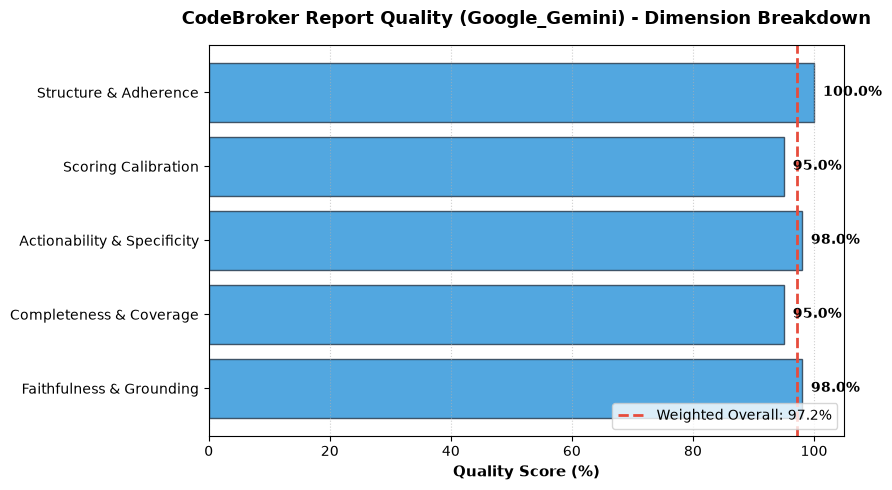

/tmp/ipykernel_68680/2209839910.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["20%", "40%", "60%", "80%", "100%"], fontsize=9)


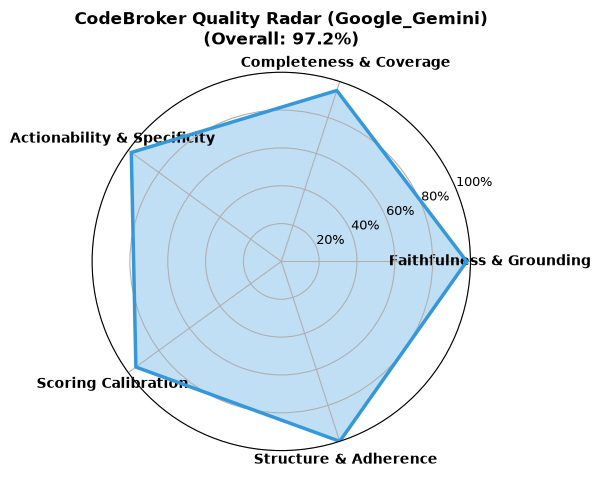

📊 Single-model charts (Google_Gemini) saved to: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/analytics_data
📄 Separate HTML Evaluation Report generated at: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation.html
📄 Separate Markdown Evaluation Report generated at: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_gemini.md

🦙 Invoking local Ollama Evaluator (llama3.2:1b)...
🏆 Ollama Overall Quality Score: 46.68%
📊 Ollama Dimension Mean: 39.02% | Std: 34.61%


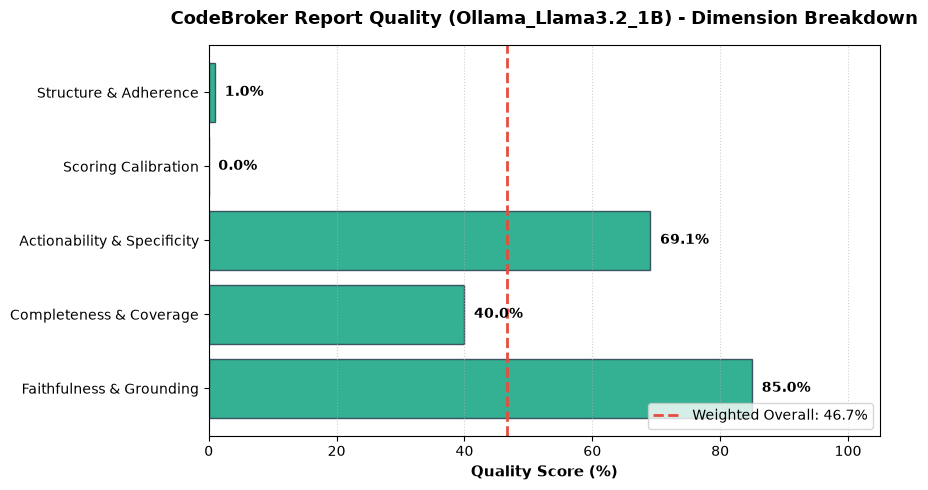

/tmp/ipykernel_68680/2209839910.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["20%", "40%", "60%", "80%", "100%"], fontsize=9)


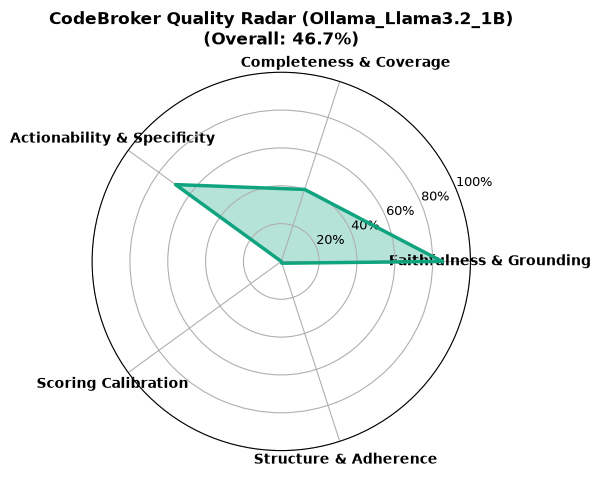

📊 Single-model charts (Ollama_Llama3.2_1B) saved to: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/analytics_data
📄 Separate HTML Evaluation Report generated at: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_ollama.html
📄 Separate Markdown Evaluation Report generated at: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_ollama.md

🦙 Invoking local Ollama Qwen Evaluator (qwen2.5:1.5b)...
🏆 Qwen Overall Quality Score: 87.00%
📊 Qwen Dimension Mean: 87.00% | Std: 2.45%


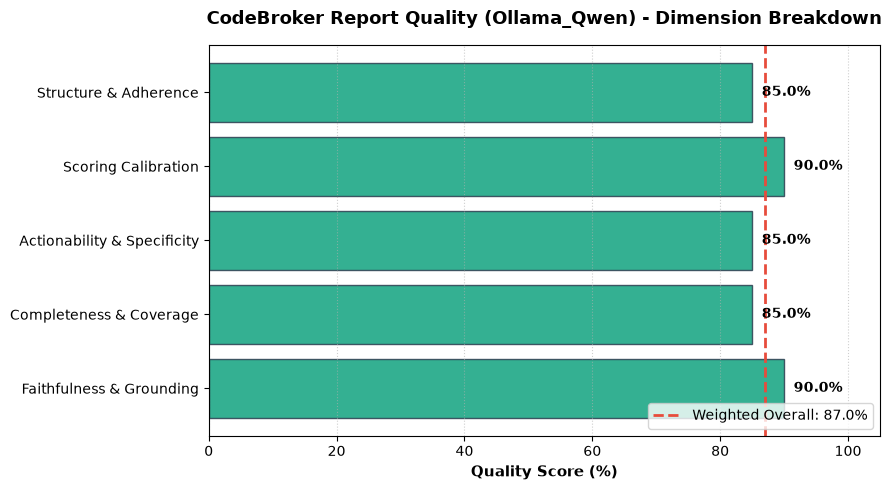

/tmp/ipykernel_68680/2209839910.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["20%", "40%", "60%", "80%", "100%"], fontsize=9)


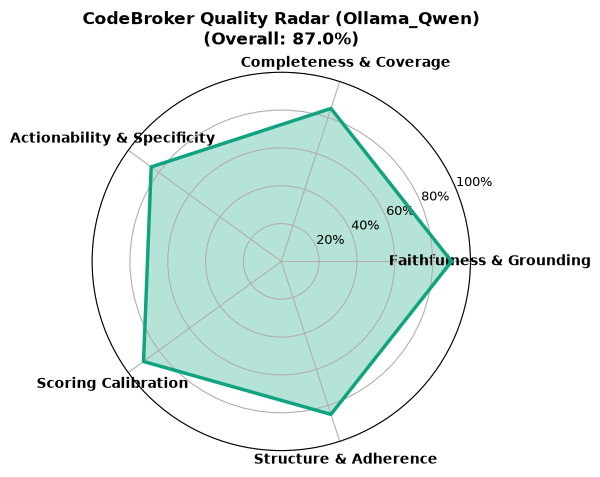

📊 Single-model charts (Ollama_Qwen) saved to: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/analytics_data
📄 Separate HTML Evaluation Report generated at: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_qwen.html
📄 Separate Markdown Evaluation Report generated at: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_qwen.md

⚖️ CROSS-MODEL JAX AGREEMENT & POLARS COMPARISON
🤝 Gemini/Llama Cosine Similarity: 0.7495
🤝 Gemini/Qwen Cosine Similarity: 0.9992
🤝 Llama/Qwen Cosine Similarity: 0.7494
📉 Gemini/Llama Mean Absolute Deviation: 58.18%
📉 Gemini/Qwen Mean Absolute Deviation: 10.20%
📉 Llama/Qwen Mean Absolute Deviation: 47.98%


### 📋 Cross-Model Side-by-Side Comparison (Polars)

Dimension,Gemini Score (%),Llama 3.2 1B Score (%),Qwen 2.5 1.5B Score (%),Delta (Llama - Gemini) (%),Delta (Qwen - Gemini) (%),Delta (Qwen - Llama) (%)
str,f64,f64,f64,f64,f64,f64
"""Faithfulness & Grounding""",98.0,85.0,90.0,-13.0,-8.0,5.0
"""Completeness & Coverage""",95.0,40.0,85.0,-55.0,-10.0,45.0
"""Actionability & Specificity""",98.0,69.099998,85.0,-28.9,-13.0,15.9
"""Scoring Calibration""",95.0,0.0,90.0,-95.0,-5.0,90.0
"""Structure & Adherence""",100.0,1.0,85.0,-99.0,-15.0,84.0


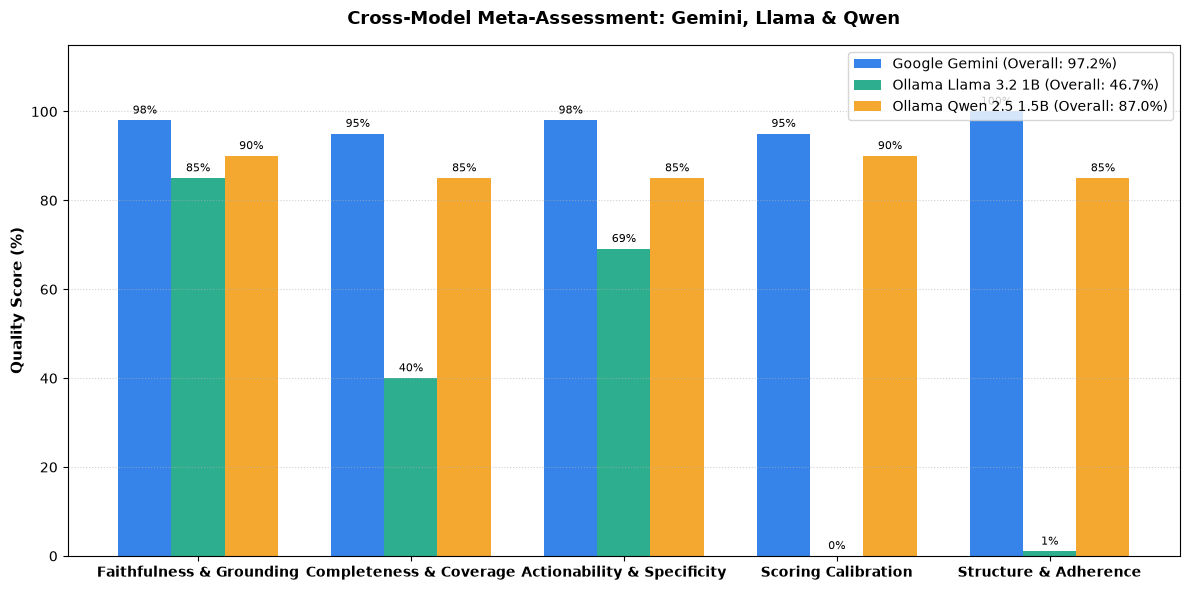

/tmp/ipykernel_68680/2209839910.py:130: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(["20%", "40%", "60%", "80%", "100%"], fontsize=9)


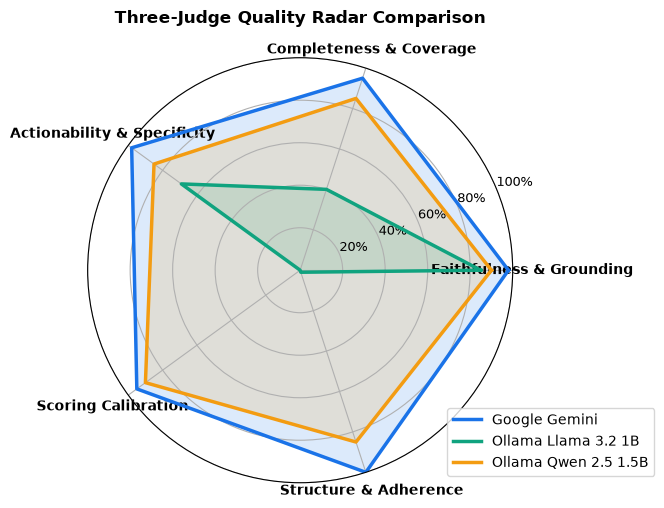

📊 Comparative charts saved to: /home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/analytics_data



### 📝 Evaluation & Reports Summary
- **Google Gemini Quality Score**: `97.2%`
- **Ollama Llama 3.2 1B Quality Score**: `46.7%`
- **Gemini / Llama Agreement**: `0.7495`
- **Gemini / Qwen Agreement**: `0.9992`
- **Llama / Qwen Agreement**: `0.7494`
- **Gemini HTML / Markdown Reports**: [code_broker_quality_meta_evaluation.html](/home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation.html) / [code_broker_quality_meta_evaluation_gemini.md](/home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_gemini.md)
- **Llama HTML / Markdown Reports**: [code_broker_quality_meta_evaluation_ollama.html](/home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_ollama.html) / [code_broker_quality_meta_evaluation_ollama.md](/home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_ollama.md)
- **Qwen HTML / Markdown Reports**: [code_broker_quality_meta_evaluation_qwen.html](/home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_qwen.html) / [code_broker_quality_meta_evaluation_qwen.md](/home/samer/Documents/studies/5-Day AI Agents Intensive kaggle/capstone_project/agents_intensive_dev/notebooks/reports/code_broker_quality_meta_evaluation_qwen.md)


In [27]:
# Define input paths
code_target_path = "../src/llm_adk_agent_module.py"
report_target_path = "reports/code_assessment_report.html"

print(f"📥 Loading source code from: {code_target_path}")
source_code = load_source_code(code_target_path)
print(f"   Loaded {len(source_code)} source file(s): {list(source_code.keys())}")

print(f"📥 Loading CodeBroker report from: {report_target_path}")
report_text = load_code_broker_report(report_target_path)
print(f"   Loaded report content ({len(report_text)} characters)")

# ==========================================
# 1. Google GenAI Evaluation (gemini-2.5-flash)
# ==========================================
print("\n" + "=" * 65)
print("🤖 Invoking Google GenAI Evaluator (gemini-2.5-flash)...")
print("=" * 65)
evaluation_gemini = evaluate_code_broker_report(
    source_code_dict=source_code,
    report_text=report_text,
    client=google_client,
    model_name="gemini-2.5-flash",
)

jax_metrics_gemini = compute_jax_quality_metrics(evaluation_gemini)
summary_df_gemini = build_polars_summary(evaluation_gemini, jax_metrics_gemini, model_name="Google Gemini")

print(f"🏆 Gemini Overall Quality Score: {jax_metrics_gemini['weighted_overall_score']:.2f}%")
print(f"📊 Gemini Dimension Mean: {jax_metrics_gemini['mean_dimension_score']:.2f}% | Std: {jax_metrics_gemini['std_dimension_score']:.2f}%")

# Save Google GenAI single model visualizations
generate_and_save_visualizations(summary_df_gemini, jax_metrics_gemini, model_name="Google_Gemini")

# Generate Google GenAI separate HTML report
html_report_gemini = generate_evaluation_html_report(
    evaluation=evaluation_gemini,
    jax_metrics=jax_metrics_gemini,
    df=summary_df_gemini,
    target_name=Path(code_target_path).name,
    output_path="reports/code_broker_quality_meta_evaluation.html",
    model_title="Google Gemini (gemini-2.5-flash)",
)
md_report_gemini = generate_evaluation_markdown_report(
    evaluation=evaluation_gemini,
    jax_metrics=jax_metrics_gemini,
    df=summary_df_gemini,
    target_name=Path(code_target_path).name,
    output_path="reports/code_broker_quality_meta_evaluation_gemini.md",
    model_title="Google Gemini (gemini-2.5-flash)",
)

# ==========================================
# 2. Local Ollama Evaluation (llama3.2:1b) & Separate Report Generation
# ==========================================
print("\n" + "=" * 65)
print("🦙 Invoking local Ollama Evaluator (llama3.2:1b)...")
print("=" * 65)

evaluation_ollama = evaluate_code_broker_report_ollama(
    source_code_dict=source_code,
    report_text=report_text,
    model_name="llama3.2:1b",
    ollama_base_url=ollama_base_url,
)

jax_metrics_ollama = compute_jax_quality_metrics(evaluation_ollama)
summary_df_ollama = build_polars_summary(
    evaluation_ollama, jax_metrics_ollama, model_name="Ollama Llama 3.2 1B"
)

print(f"🏆 Ollama Overall Quality Score: {jax_metrics_ollama['weighted_overall_score']:.2f}%")
print(f"📊 Ollama Dimension Mean: {jax_metrics_ollama['mean_dimension_score']:.2f}% | Std: {jax_metrics_ollama['std_dimension_score']:.2f}%")

generate_and_save_visualizations(
    summary_df_ollama, jax_metrics_ollama, model_name="Ollama_Llama3.2_1B"
)

html_report_ollama = generate_evaluation_html_report(
    evaluation=evaluation_ollama,
    jax_metrics=jax_metrics_ollama,
    df=summary_df_ollama,
    target_name=Path(code_target_path).name,
    output_path="reports/code_broker_quality_meta_evaluation_ollama.html",
    model_title="Ollama (llama3.2:1b)",
)

md_report_ollama = generate_evaluation_markdown_report(
    evaluation=evaluation_ollama,
    jax_metrics=jax_metrics_ollama,
    df=summary_df_ollama,
    target_name=Path(code_target_path).name,
    output_path="reports/code_broker_quality_meta_evaluation_ollama.md",
    model_title="Ollama (llama3.2:1b)",
)

# ==========================================
# 3. Local Ollama Qwen Evaluation & Separate Report Generation
# ==========================================
print("\n" + "=" * 65)
print(f"🦙 Invoking local Ollama Qwen Evaluator ({qwen_model_name})...")
print("=" * 65)

evaluation_qwen = evaluate_code_broker_report_ollama(
    source_code_dict=source_code,
    report_text=report_text,
    model_name=qwen_model_name,
    ollama_base_url=ollama_base_url,
)
jax_metrics_qwen = compute_jax_quality_metrics(evaluation_qwen)
summary_df_qwen = build_polars_summary(
    evaluation_qwen, jax_metrics_qwen, model_name=f"Ollama {qwen_model_name}"
)
print(f"🏆 Qwen Overall Quality Score: {jax_metrics_qwen['weighted_overall_score']:.2f}%")
print(f"📊 Qwen Dimension Mean: {jax_metrics_qwen['mean_dimension_score']:.2f}% | Std: {jax_metrics_qwen['std_dimension_score']:.2f}%")
generate_and_save_visualizations(
    summary_df_qwen, jax_metrics_qwen, model_name="Ollama_Qwen"
)
html_report_qwen = generate_evaluation_html_report(
    evaluation=evaluation_qwen,
    jax_metrics=jax_metrics_qwen,
    df=summary_df_qwen,
    target_name=Path(code_target_path).name,
    output_path="reports/code_broker_quality_meta_evaluation_qwen.html",
    model_title=f"Ollama ({qwen_model_name})",
)
md_report_qwen = generate_evaluation_markdown_report(
    evaluation=evaluation_qwen,
    jax_metrics=jax_metrics_qwen,
    df=summary_df_qwen,
    target_name=Path(code_target_path).name,
    output_path="reports/code_broker_quality_meta_evaluation_qwen.md",
    model_title=f"Ollama ({qwen_model_name})",
)

# ==========================================
# 4. Cross-Model JAX & Polars Comparison
# ==========================================
print("\n" + "=" * 65)
print("⚖️ CROSS-MODEL JAX AGREEMENT & POLARS COMPARISON")
print("=" * 65)

comparison_metrics, df_comparison = compare_evaluations_jax_polars(
    evaluation_gemini=evaluation_gemini,
    evaluation_llama=evaluation_ollama,
    evaluation_qwen=evaluation_qwen,
    jax_metrics_gemini=jax_metrics_gemini,
    jax_metrics_llama=jax_metrics_ollama,
    jax_metrics_qwen=jax_metrics_qwen,
)

print(f"🤝 Gemini/Llama Cosine Similarity: {comparison_metrics['cosine_similarity_llama_gemini']:.4f}")
print(f"🤝 Gemini/Qwen Cosine Similarity: {comparison_metrics['cosine_similarity_qwen_gemini']:.4f}")
print(f"🤝 Llama/Qwen Cosine Similarity: {comparison_metrics['cosine_similarity_qwen_llama']:.4f}")
print(f"📉 Gemini/Llama Mean Absolute Deviation: {comparison_metrics['mean_absolute_difference_llama_gemini']:.2f}%")
print(f"📉 Gemini/Qwen Mean Absolute Deviation: {comparison_metrics['mean_absolute_difference_qwen_gemini']:.2f}%")
print(f"📉 Llama/Qwen Mean Absolute Deviation: {comparison_metrics['mean_absolute_difference_qwen_llama']:.2f}%")

# Display Comparison Polars Table
display(Markdown("### 📋 Cross-Model Side-by-Side Comparison (Polars)"))
display(df_comparison.select([
    "Dimension",
    "Gemini Score (%)",
    "Llama 3.2 1B Score (%)",
    "Qwen 2.5 1.5B Score (%)",
    "Delta (Llama - Gemini) (%)",
    "Delta (Qwen - Gemini) (%)",
    "Delta (Qwen - Llama) (%)"
]))

# Generate and save Comparative Visualizations to analytics_data
comp_charts = generate_comparative_visualizations(
    df_comparison=df_comparison,
    jax_metrics_gemini=jax_metrics_gemini,
    jax_metrics_llama=jax_metrics_ollama,
    jax_metrics_qwen=jax_metrics_qwen,
    output_dir="../analytics_data",
)

display(Markdown(f"""
### 📝 Evaluation & Reports Summary
- **Google Gemini Quality Score**: `{jax_metrics_gemini['weighted_overall_score']:.1f}%`
- **Ollama Llama 3.2 1B Quality Score**: `{jax_metrics_ollama['weighted_overall_score']:.1f}%`
- **Gemini / Llama Agreement**: `{comparison_metrics['cosine_similarity_llama_gemini']:.4f}`
- **Gemini / Qwen Agreement**: `{comparison_metrics['cosine_similarity_qwen_gemini']:.4f}`
- **Llama / Qwen Agreement**: `{comparison_metrics['cosine_similarity_qwen_llama']:.4f}`
- **Gemini HTML / Markdown Reports**: [{Path(html_report_gemini).name}]({html_report_gemini}) / [{Path(md_report_gemini).name}]({md_report_gemini})
- **Llama HTML / Markdown Reports**: [{Path(html_report_ollama).name}]({html_report_ollama}) / [{Path(md_report_ollama).name}]({md_report_ollama})
- **Qwen HTML / Markdown Reports**: [{Path(html_report_qwen).name}]({html_report_qwen}) / [{Path(md_report_qwen).name}]({md_report_qwen})
"""))
